# 🫁 AMIA Public Challenge 2026 - Classifying common thoracic lung diseases and localizing critical findings 
## Using RT-DETR: A Vision Transformer-Based Real-Time Object Detector
Priscilla, Maham, Mary, Zuriel

In this competition, we have to automatically localize and classify 14 types of thoracic abnormalities from chest radiographs. The subset is based on a dataset consisting of a total of 15,000 scans that have been annotated by experienced radiologists. From those, 8,573 images have been used for training and 6,427 images for testing. The train csv contains 45,925 rows and the test csv 21,989.

Details on building the dataset can be found in a recent paper “VinDr-CXR: An open dataset of chest X-rays with radiologist's annotations”.

### Data Description
This is an object detection and classification problem.

For each test image, we will be predicting a bounding box and class for all findings. If you predict that there are no findings, you should create a prediction of "14 1 0 0 1 1" (14 is the class ID for no finding, and this provides a one-pixel bounding box with a confidence of 1.0).

The images are in PNG format and resized to 1024x1024 pixels.

The dataset comprises 15,000 postero-anterior (PA) CXR scans in PNG format. All images were labeled by a panel of experienced radiologists for the presence of 14 critical radiographic findings.

## Set up

We will need ultralytics for YOLOv8. YOLOv8 employs state-of-the-art backbone and neck architectures, resulting in improved feature extraction and object detection performance.

In [11]:
!pip install -q -U ultralytics

W&B Models helps you pre-train, fine-tune, govern, and manage models from experimentation to production, accelerating time to market. 

In [12]:
!pip install -q wandb

import wandb
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("WANDB_KEY")

wandb.login(key=secret_value_0)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


True

In [13]:
import pandas as pd
import numpy as np

from pathlib import Path
import shutil

from sklearn.model_selection import train_test_split
from ultralytics import RTDETR
# for validating data pipeline
from collections import Counter

import random
import textwrap
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import matplotlib.patches as patches


### Configurations

This section defines the paths, model name, training settings, and prediction thresholds.

The model is set to `rtdetr-l.pt`.

RT-DETR efficiently processes multiscale features by decoupling intra-scale interaction and cross-scale fusion. The model is highly adaptable, supporting flexible adjustment of inference speed using different decoder layers without retraining. 

In [14]:
COMP_DIR = Path("/kaggle/input/competitions/amia-public-challenge-2026")
WORK_DIR = Path("/kaggle/working/yolo_data")
RUN_DIR = Path("/kaggle/working/runs")
OUT_CSV = Path("/kaggle/working/submission.csv")

TRAIN_IMG_DIR = COMP_DIR / "train" / "train"
TEST_IMG_DIR = COMP_DIR / "test" / "test"

TRAIN_CSV = COMP_DIR / "train.csv"
IMG_SIZE_CSV = COMP_DIR / "img_size.csv"
SAMPLE_SUB = COMP_DIR / "sample_submission.csv"

RUN_NAME = "rtdetr_baseline"

MODEL = "rtdetr-l.pt"
EPOCHS = 50
IMG_SIZE = 640
BATCH = 8
CONF = 0.2
IOU = 0.40

NO_FINDING = 14
NC = 14

In [15]:
train_df   = pd.read_csv(COMP_DIR / "train.csv")
test_df    = pd.read_csv(COMP_DIR / "test.csv")
img_size   = pd.read_csv(COMP_DIR / "img_size.csv")
sample_sub = pd.read_csv(COMP_DIR / "sample_submission.csv")

print(f"Train  : {train_df.shape}")
print(f"Test   : {test_df.shape}")
print(f"ImgSz  : {img_size.shape}")
print(f"Sub    : {sample_sub.shape}")
print()
print(train_df.head(4).to_string())

Train  : (45925, 8)
Test   : (21989, 1)
ImgSz  : (15000, 3)
Sub    : (6427, 2)

                           image_id          class_name  class_id rad_id   x_min  y_min   x_max   y_max
0  bM8C97htulC9fHKIDurJHquCXr1KZuug          No finding        14     R5     NaN    NaN     NaN     NaN
1  0FDQVdLgDKI1sRnPL94LzVh9EvXDVM9m  Aortic enlargement         0    R10  1148.0  503.0  1466.0   823.0
2  Dwk2TnGJFaMhyi3OfCrhdZG9ppGglC5w       Consolidation         4     R8   264.0  732.0   550.0  1119.0
3  vqw6mWifHgCf8jmTotrMAS3qCk5eJuc4          No finding        14    R13     NaN    NaN     NaN     NaN


In [16]:
# How many unique images in train vs test?
train_ids = train_df["image_id"].nunique()
test_ids  = test_df["image_id"].nunique()
print(f"Unique train images : {train_ids}")
print(f"Unique test images  : {test_ids}")
print(f"Avg annotations/img : {len(train_df) / train_ids:.1f}")

# Separate 'No finding' images from positive ones
no_finding    = train_df[train_df["class_id"] == 14]
has_finding   = train_df[train_df["class_id"] != 14]
print(f"\nImages with 'No finding' : {no_finding['image_id'].nunique()}")
print(f"Images with findings     : {has_finding['image_id'].nunique()}")

Unique train images : 8573
Unique test images  : 6427
Avg annotations/img : 5.4

Images with 'No finding' : 5175
Images with findings     : 3398


### Quick EDA
For detection, check the following:

1. Class distribution — how severe is the imbalance across the 14 findings?

2. Annotation density — how many boxes per image on average?

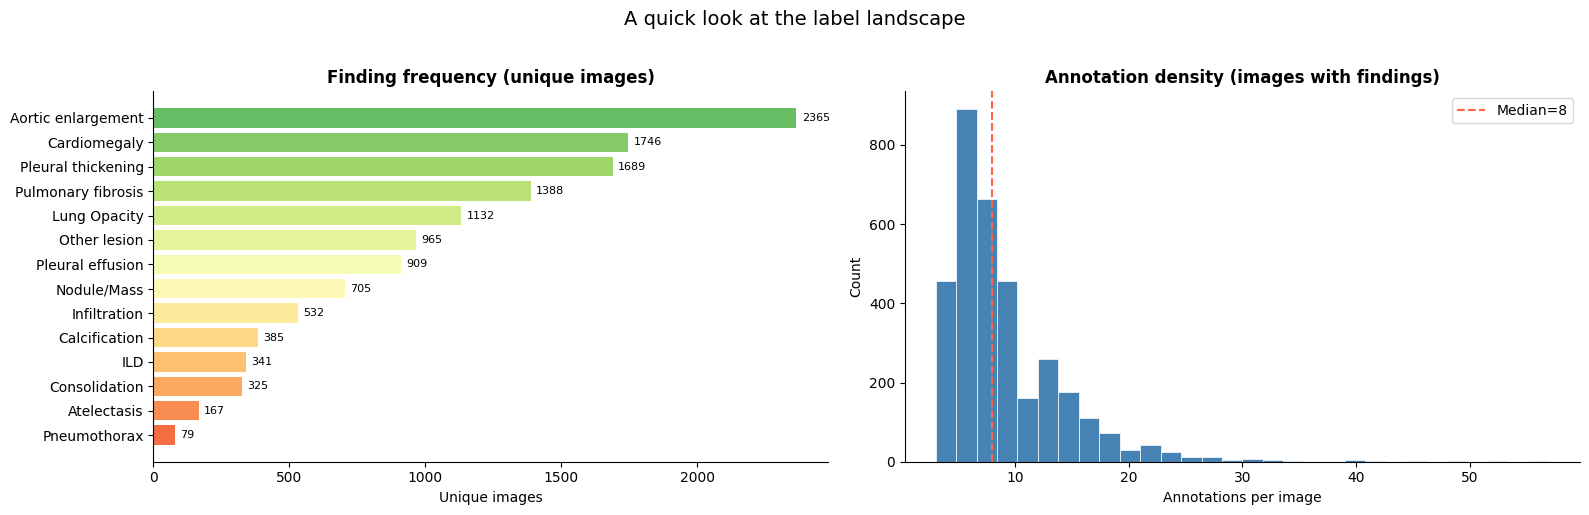


Imbalance ratio (most / least common finding): 29.9x


In [17]:
# ── Class distribution (excluding No Finding) ─────────────────────────────────
finding_counts = (
    has_finding.groupby("class_name")["image_id"]
    .nunique()
    .sort_values(ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: finding frequency
colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(finding_counts)))
axes[0].barh(finding_counts.index, finding_counts.values, color=colors)
axes[0].set_xlabel("Unique images")
axes[0].set_title("Finding frequency (unique images)", fontweight="bold")
axes[0].spines[["top", "right"]].set_visible(False)
for i, v in enumerate(finding_counts.values):
  axes[0].text(v + 20, i, str(v), va="center", fontsize=8)

# Right: annotations per image distribution
ann_per_img = has_finding.groupby("image_id").size()
axes[1].hist(ann_per_img, bins=30, color="steelblue", edgecolor="white", linewidth=0.5)
axes[1].set_xlabel("Annotations per image")
axes[1].set_ylabel("Count")
axes[1].set_title("Annotation density (images with findings)", fontweight="bold")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].axvline(ann_per_img.median(), color="tomato", linestyle="--", label=f"Median={ann_per_img.median():.0f}")
axes[1].legend()

plt.suptitle("A quick look at the label landscape", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print(f"\nImbalance ratio (most / least common finding): "
      f"{finding_counts.max() / finding_counts.min():.1f}x")

## Data Standardization and Organization Pipeline:
'make_dataset()' function does the following
1. read the raw competition CSVs,
2. stripped out all "No Finding" annotation rows (class 14) from the dataframe,
3. then scanned every .png on disk to build the full image list.
4. It split all images 85/15 into train and val using train_test_split randomely,
5. copied each image into the YOLO folder structure, and wrote a .txt label file per image — populated with normalized bounding boxes for images that had findings (in the .txt), and left empty for images that didn't.

In [18]:
def key(x):
    """The CSV may store image IDs with or without `.png`. This helper standardizes image IDs by removing any file extension."""
    return Path(str(x)).stem

In [19]:
def make_dataset():
    train = pd.read_csv(TRAIN_CSV)
    sizes = pd.read_csv(IMG_SIZE_CSV)

    size_lookup = {
        key(r.image_id): (float(r.dim0), float(r.dim1))
        for r in sizes.itertuples(index=False)
    }

    train["image_key"] = train["image_id"].map(key)
    # This following code needs to be here
    # it removes the labels for no findings, classifying them to background images as YOLO format requires
    train = train[train["class_id"] != NO_FINDING].copy() 

    image_ids = sorted([p.stem for p in TRAIN_IMG_DIR.glob("*.png")])
    train_ids, val_ids = train_test_split(image_ids, test_size=0.15, random_state=42)

    if WORK_DIR.exists():
        shutil.rmtree(WORK_DIR)

    for split, ids in [("train", train_ids), ("val", val_ids)]:
        (WORK_DIR / "images" / split).mkdir(parents=True)
        (WORK_DIR / "labels" / split).mkdir(parents=True)

        for image_id in ids:
            src = TRAIN_IMG_DIR / f"{image_id}.png"
            dst = WORK_DIR / "images" / split / src.name
            shutil.copy2(src, dst)

            orig_h, orig_w = size_lookup[image_id]
            rows = train[train["image_key"] == image_id]

            lines = []

            for r in rows.itertuples(index=False):
                x1 = max(0, min(float(r.x_min), orig_w - 1))
                y1 = max(0, min(float(r.y_min), orig_h - 1))
                x2 = max(0, min(float(r.x_max), orig_w - 1))
                y2 = max(0, min(float(r.y_max), orig_h - 1))

                if x2 <= x1 or y2 <= y1:
                    continue

                xc = ((x1 + x2) / 2) / orig_w
                yc = ((y1 + y2) / 2) / orig_h
                bw = (x2 - x1) / orig_w
                bh = (y2 - y1) / orig_h

                lines.append(f"{int(r.class_id)} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

            (WORK_DIR / "labels" / split / f"{image_id}.txt").write_text("\n".join(lines))

    yaml_path = WORK_DIR / "data.yaml"
    yaml_path.write_text(
        f"path: {WORK_DIR}\n"
        "train: images/train\n"
        "val: images/val\n"
        "names:\n"
        + "\n".join([f"  {i}: class_{i}" for i in range(NC)])
        + "\n"
    )

    return yaml_path, size_lookup

In [20]:
yaml_path, size_lookup = make_dataset()

In [21]:
def audit_dataset():

    SPLITS = ["train", "val"]

    print("=" * 55)
    print("  DATASET STRUCTURE AUDIT")
    print("=" * 55)

    for split in SPLITS:
        img_dir = WORK_DIR / "images" / split
        lbl_dir = WORK_DIR / "labels" / split

        img_files = sorted(img_dir.glob("*.png"))
        lbl_files = sorted(lbl_dir.glob("*.txt"))

        empty_labels    = [f for f in lbl_files if f.stat().st_size == 0]
        nonempty_labels = [f for f in lbl_files if f.stat().st_size > 0]

        print(f"\n  [{split.upper()}]")
        print(f"    Images            : {len(img_files)}")
        print(f"    Label files       : {len(lbl_files)}")
        print(f"    With findings     : {len(nonempty_labels)}")
        print(f"    No finding (empty): {len(empty_labels)}")

        class_counts = Counter()
        for lbl in nonempty_labels:
            for line in lbl.read_text().strip().splitlines():
                cls = int(line.split()[0])
                class_counts[cls] += 1

        if class_counts:
            print(f"    Class distribution:")
            for cls, count in sorted(class_counts.items()):
                print(f"      class_{cls:>2} : {count} boxes")

    total = sum(len(list((WORK_DIR / "images" / s).glob("*.png"))) for s in SPLITS)
    print("\n" + "=" * 55)
    print(f"  TOTAL IMAGES (train + val): {total}")
    print("=" * 55)

In [22]:
audit_dataset()

  DATASET STRUCTURE AUDIT

  [TRAIN]
    Images            : 7287
    Label files       : 7287
    With findings     : 2897
    No finding (empty): 4390
    Class distribution:
      class_ 0 : 4690 boxes
      class_ 1 : 214 boxes
      class_ 2 : 727 boxes
      class_ 3 : 3461 boxes
      class_ 4 : 465 boxes
      class_ 5 : 732 boxes
      class_ 6 : 938 boxes
      class_ 7 : 1879 boxes
      class_ 8 : 2038 boxes
      class_ 9 : 1672 boxes
      class_10 : 1907 boxes
      class_11 : 3687 boxes
      class_12 : 172 boxes
      class_13 : 3420 boxes

  [VAL]
    Images            : 1286
    Label files       : 1286
    With findings     : 501
    No finding (empty): 785
    Class distribution:
      class_ 0 : 791 boxes
      class_ 1 : 41 boxes
      class_ 2 : 124 boxes
      class_ 3 : 585 boxes
      class_ 4 : 54 boxes
      class_ 5 : 172 boxes
      class_ 6 : 159 boxes
      class_ 7 : 309 boxes
      class_ 8 : 286 boxes
      class_ 9 : 273 boxes
      class_10 : 283 b

### The result after data pipeline:

We have 8,573 total images split into 7,287 train / 1,286 val.
Of those, only 2,897 train images (39.8%) and 501 val images (38.9%) actually have pathology boxes. 
The remaining 4,390 train and 785 val images are empty-label background images — meaning 60% of the dataset is "No Finding" cases.
Other classes distribution is listed above

### Visualizing the dataset pre-training

In [23]:
def visualize_pre_training(n_samples=6, seed=42):
    """
    Shows n_samples random images in 3 columns:
      - Original image (raw from disk, no resize)
      - Scaled image (resized to IMG_SIZE x IMG_SIZE)
      - Scaled image with YOLO bounding boxes + class labels overlaid
    Only selects images that have at least one finding (non-empty label).
    """

    CLASS_NAMES = [
        "Aortic enlargement",   # 0
        "Atelectasis",          # 1
        "Calcification",        # 2
        "Cardiomegaly",         # 3
        "Consolidation",        # 4
        "ILD",                  # 5
        "Infiltration",         # 6
        "Lung Opacity",         # 7
        "Nodule/Mass",          # 8
        "Other lesion",         # 9
        "Pleural effusion",     # 10
        "Pleural thickening",   # 11
        "Pneumothorax",         # 12
        "Pulmonary fibrosis",   # 13
    ]

    COLORS = [
        "#FF6B6B","#FFD93D","#6BCB77","#4D96FF","#FF922B",
        "#CC5DE8","#20C997","#F06595","#74C0FC","#A9E34B",
        "#FF8787","#63E6BE","#FFA94D","#DA77F2",
    ]

    # Collect images that have findings
    train_lbl_dir = WORK_DIR / "labels" / "train"
    train_img_dir = WORK_DIR / "images" / "train"

    labeled = [f for f in sorted(train_lbl_dir.glob("*.txt")) if f.stat().st_size > 0]
    random.seed(seed)
    samples = random.sample(labeled, min(n_samples, len(labeled)))

    fig, axes = plt.subplots(n_samples, 3, figsize=(18, n_samples * 5))
    fig.patch.set_facecolor("#0d1117")

    col_titles = ["Original", f"Scaled ({IMG_SIZE}×{IMG_SIZE})", "Boxes + Labels"]
    for col, title in enumerate(col_titles):
        axes[0][col].set_title(title, color="white", fontsize=13,
                               fontweight="bold", pad=10)

    for row, lbl_file in enumerate(samples):
        stem = lbl_file.stem

        # --- load images ---
        orig_path = TRAIN_IMG_DIR / f"{stem}.png"
        orig = Image.open(orig_path).convert("RGB")
        orig_w, orig_h = orig.size

        scaled = orig.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

        # --- parse YOLO labels (cx cy w h normalized) ---
        boxes = []
        for line in lbl_file.read_text().strip().splitlines():
            parts = line.split()
            cls = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:5])
            # convert to pixel coords on scaled image
            x1 = (cx - bw / 2) * IMG_SIZE
            y1 = (cy - bh / 2) * IMG_SIZE
            x2 = (cx + bw / 2) * IMG_SIZE
            y2 = (cy + bh / 2) * IMG_SIZE
            boxes.append((cls, x1, y1, x2, y2))

        # --- col 0: original ---
        ax = axes[row][0]
        ax.imshow(orig, cmap="gray" if orig.mode == "L" else None)
        ax.set_xlabel(f"{orig_w}×{orig_h}px", color="#8b949e", fontsize=9)
        ax.set_title(f"{stem[:18]}…" if len(stem) > 18 else stem,
                     color="#8b949e", fontsize=8, pad=4)

        # --- col 1: scaled, no boxes ---
        ax = axes[row][1]
        ax.imshow(scaled)
        ax.set_xlabel(f"{IMG_SIZE}×{IMG_SIZE}px", color="#8b949e", fontsize=9)

        # --- col 2: scaled + boxes ---
        ax = axes[row][2]
        ax.imshow(scaled)
        for (cls, x1, y1, x2, y2) in boxes:
            color = COLORS[cls % len(COLORS)]
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=2, edgecolor=color, facecolor="none"
            )
            ax.add_patch(rect)
            label = CLASS_NAMES[cls] if cls < len(CLASS_NAMES) else f"cls_{cls}"
            ax.text(
                x1 + 3, y1 - 5, label,
                color="white", fontsize=7.5, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor=color, alpha=0.85, linewidth=0)
            )
        ax.set_xlabel(f"{len(boxes)} box(es)", color="#8b949e", fontsize=9)

        # style all 3 axes in this row
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_edgecolor("#30363d")
            ax.set_facecolor("#161b22")

    plt.suptitle("Pre-Training Data Visualization", color="white",
                 fontsize=16, fontweight="bold", y=1.01)
    plt.tight_layout(pad=1.5)
    plt.show()
    print(f"Showing {n_samples} random images with findings from training set.")

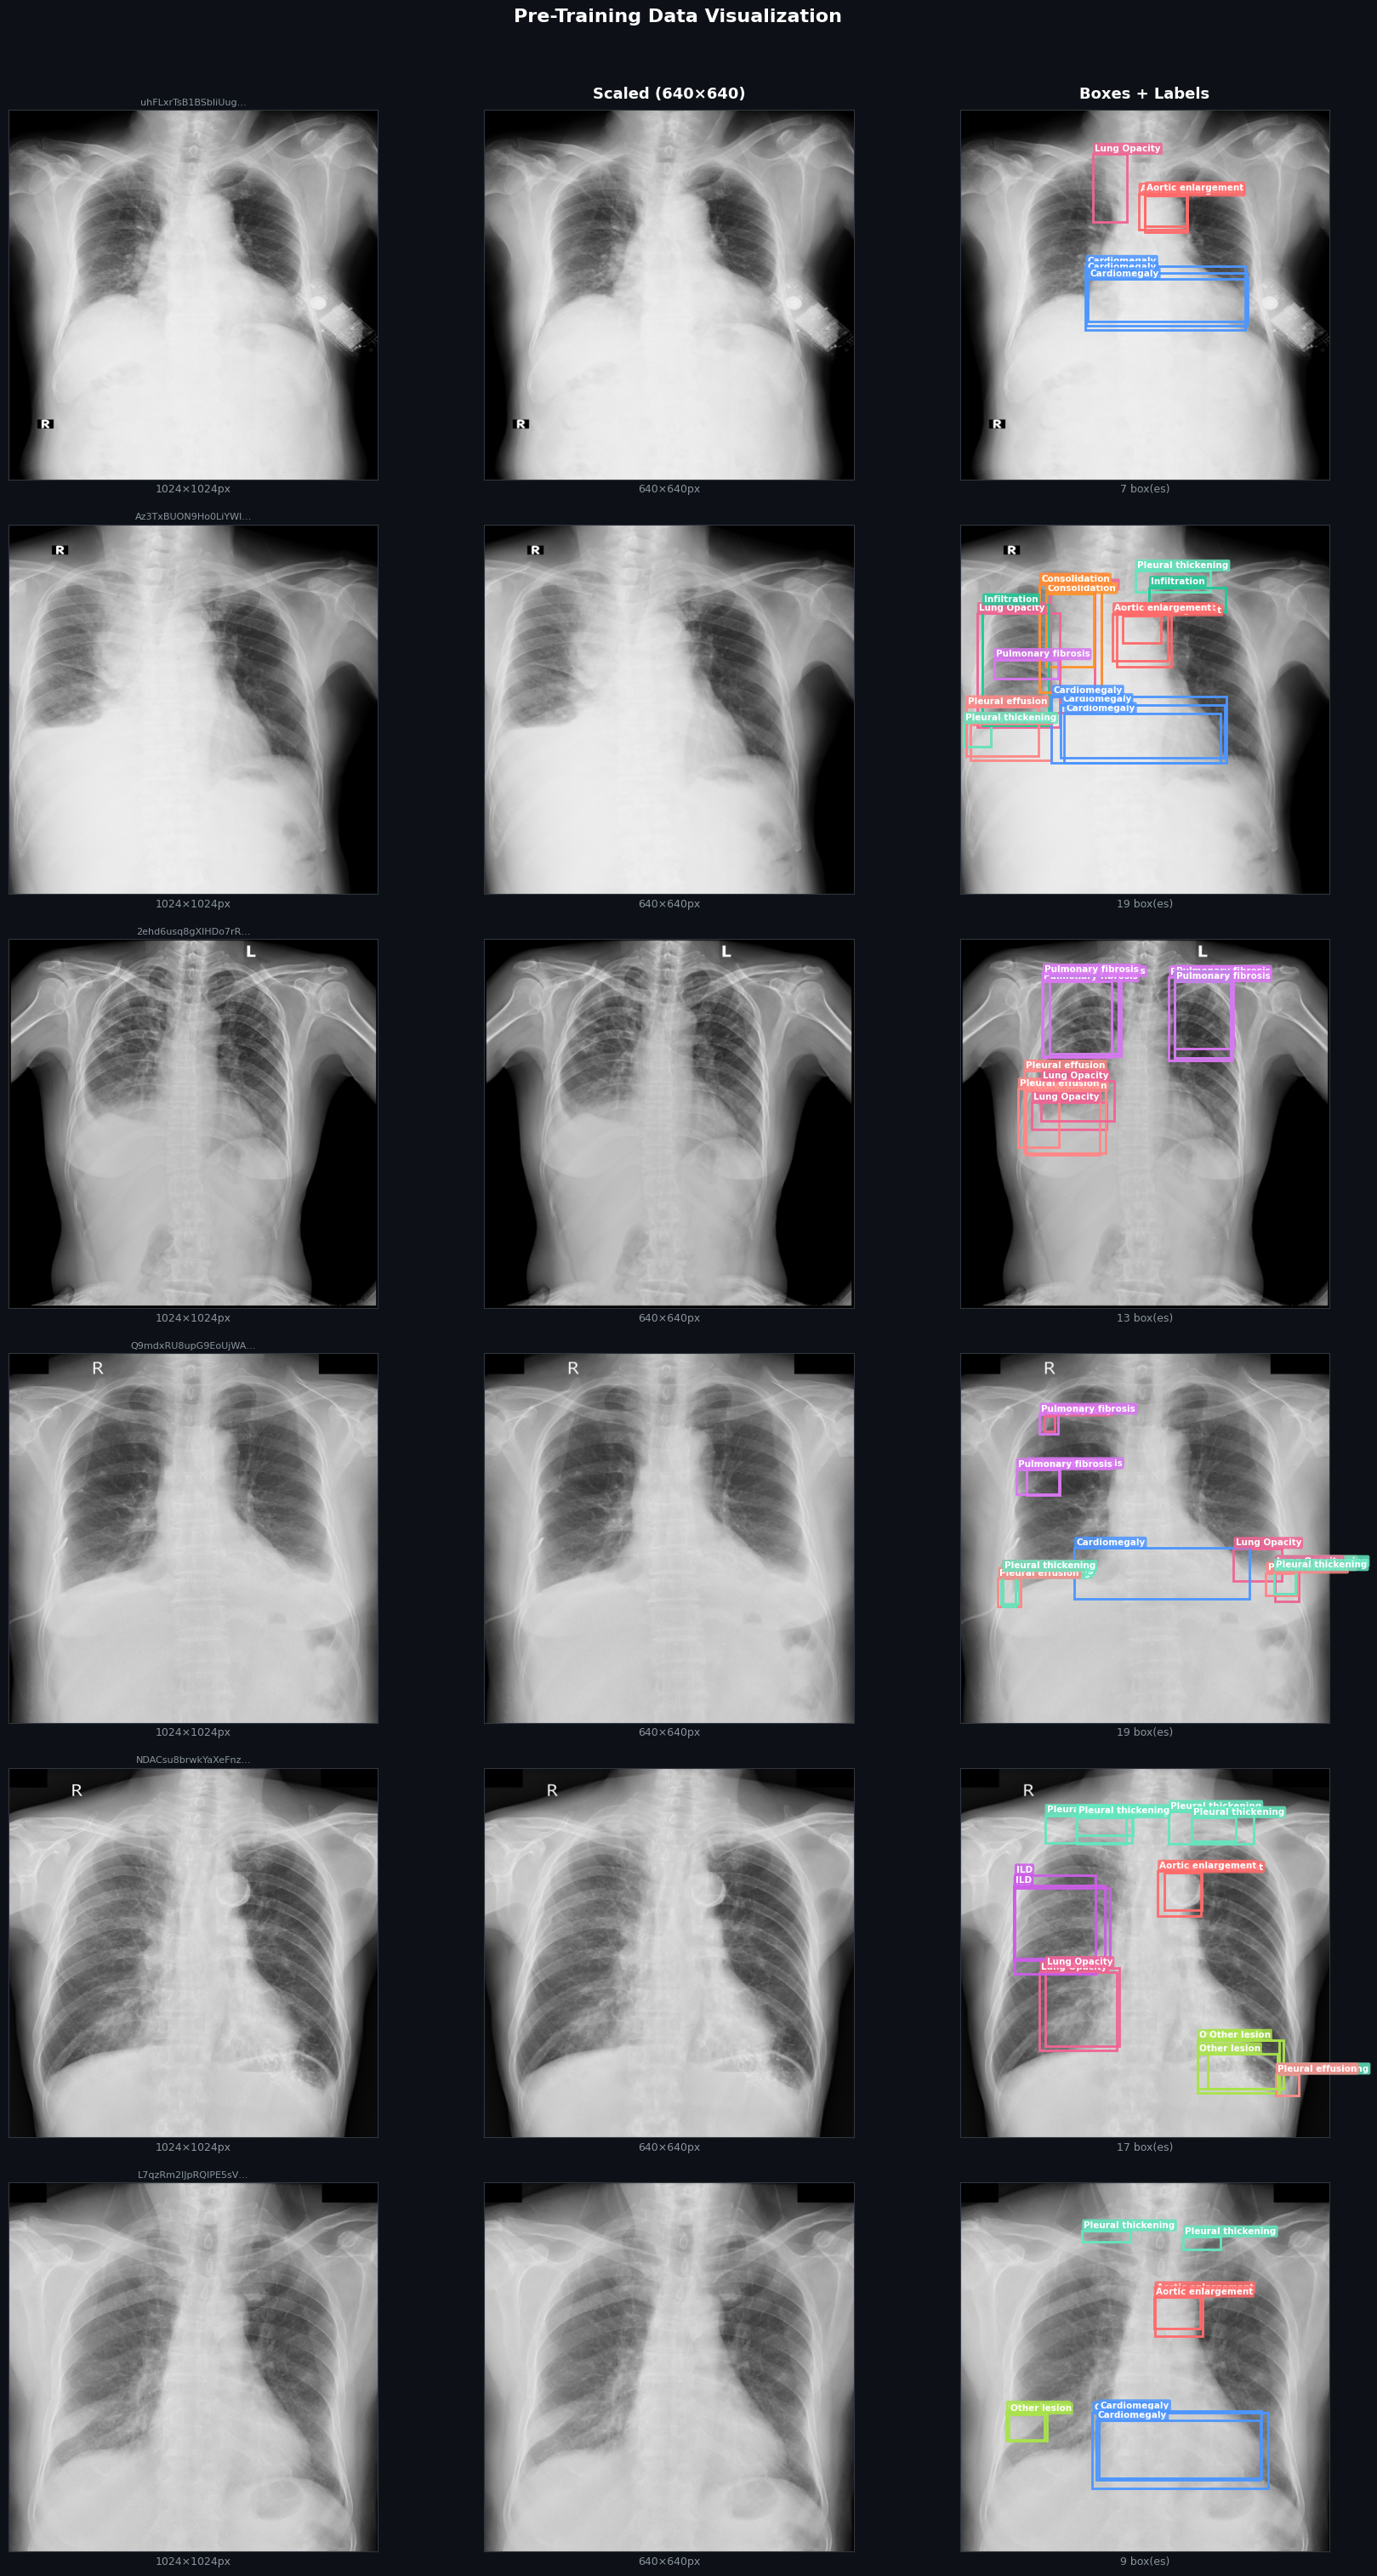

Showing 6 random images with findings from training set.


In [24]:
visualize_pre_training(n_samples=6)

## Model Training

The model is initialized from pretrained weights and trained on the converted YOLO dataset.

Ultralytics automatically saves two important checkpoints:

last.pt: weights from the final epoch
best.pt: weights from the best validation epoch
For inference, we load best.pt.

### Key training choices:

- **Batch = 16**: balances the memory usage as well as the training efficiency.

 * We also tried Batch = 32, which gets Out of Memory error; and Batch = 8, which the training isn't very efficient
- **Epoch = 50**: allows the model to meaningfully explore and converge without runtime being too long.
  * We tested the pipeline on lower epochs from 1 to 5 before running on a larger epoch size. Initially, we ran Epoch = 100 but found the return is diminishing.
- **Early stopping with patience=10**: to prevent premature stopping before the model has converged, the training loop saves the last model and the best model, compares their mAP performance, early stopping will only apply when the best model has outperformed 10 consecutive models.
  * We've also tried patience = 5 and patience = 15. The former is too short for the model to converge, while the latter wastes a lot of compute on no additional gains.
- **Learning Rate = cosine learning rate schedule**: Learning rate following a cosine curve that gradually decrease.
 * We also tried setting learning rate to 1e-3, which performs better than cosine learning rate on initial epochs, but the increased accuracy is not as consistent as the cosin learning rate. 
- **AMP = True**: Using half precision to make training more feasible within the GPU limit
- **device = [0,1]**: Using 2 Distributed Data Parrallel, each GPU gets its own copy of the model and half of the batch independently, then loss is average.
- **CONF = 0.2**: A confidence threshold of 0.2 means that if the model predicts an image with confidence lower than 0.2, the model treats the sample as "no finding".
  * We also tried CONF = 0.05. With visualizations we found it to be too low such that the model is capturing many false positives


In [25]:
def track(run_dir, run_name):
    """
    This function tracks the loss, map, learning rate, precision, and recall
    Load Ultralytics training logs and return a structured dataframe
    """
    results_path = Path(run_dir) / run_name / "results.csv"

    if not results_path.exists():
        raise FileNotFoundError(f"{results_path} not found")

    df = pd.read_csv(results_path)

    # Clean column names (Ultralytics uses spaces sometimes)
    df.columns = [c.strip() for c in df.columns]

    # Keep only useful metrics if they exist
    cols = []
    for c in df.columns:
        if any(k in c.lower() for k in ["loss", "map", "lr", "precision", "recall"]):
            cols.append(c)

    tracked_df = df[cols].copy()

    return tracked_df

In [26]:
def train_model(yaml_path):
    with wandb.init(project="amia-rtdetr", name=RUN_NAME, config={
        "model": MODEL,
        "epochs": EPOCHS,
        "img_size": IMG_SIZE,
        "batch": BATCH,
        "conf": CONF,
        "iou": IOU,
    }):
        model = RTDETR(MODEL)
        model.train(
            data=str(yaml_path),
            epochs=EPOCHS,
            imgsz=IMG_SIZE,
            batch=BATCH*2,
            project=str(RUN_DIR),
            name=RUN_NAME,
            exist_ok=True,
            patience=10,
            device=[0, 1],
            amp=True,
            cos_lr=True,
            workers=4,
            plots=True,
        )

        metrics_df = track(RUN_DIR, RUN_NAME)
        for _, row in metrics_df.iterrows():
            wandb.log(row.to_dict())

    return RTDETR(str(Path(RUN_DIR / RUN_NAME / "weights" / "best.pt")))

In [27]:
model = train_model(yaml_path)


Ultralytics 8.4.46 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
                                                       CUDA:1 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr_baseline

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution

       1/50      6.55G      1.209      2.743     0.6203         26        640: 100% ━━━━━━━━━━━━ 456/456 1.4it/s 5:26<0.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 2.5it/s 16.6s0.3s
                   all       1286       4398      0.243      0.171     0.0753     0.0415

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution

       2/50      6.94G     0.7278     0.9256     0.2905         28        640: 100% ━━━━━━━━━━━━ 456/456 1.5it/s 5:09<0.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 3.0it/s 13.6s0.3s
                   all       1286       4398      0.248      0.214       0.11     0.0623

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


...

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution

      49/50      6.95G     0.4698     0.5825     0.1885         14        640: 100% ━━━━━━━━━━━━ 456/456 1.5it/s 5:04<0.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 3.0it/s 13.7s0.3s
                   all       1286       4398      0.383      0.377      0.291      0.158

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution

      50/50      6.95G     0.4724     0.5824      0.189         16        640: 100% ━━━━━━━━━━━━ 456/456 1.5it/s 5:04<0.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 3.0it/s 13.8s0.3s
                   all       1286       4398      0.363       0.39       0.29      0.157
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 40, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

50 epochs completed in 4.457 hours.
Optimizer stripped from /kaggle/working/runs/rtdetr_baseline/weights/last.pt, 66.3MB
Optimizer stripped from /kaggle/working/runs/rtdetr_baseline/weights/best.pt, 66.3MB

Validating /kaggle/working/runs/rtdetr_baseline/weights/best.pt...
rt-detr-l summary: 310 layers, 32,012,510 parameters, 0 gradients, 103.5 GFLOPs
                 Class 

lr/pg0,▃▆██████▇▇▇▇▇▇▆▆▆▆▅▅▅▄▄▄▄▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁
lr/pg1,▃▆██████▇▇▇▇▇▇▆▆▆▅▅▅▅▄▄▄▄▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁
lr/pg2,▃▆█████▇▇▇▇▇▇▆▆▆▆▅▅▅▅▄▄▄▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁
metrics/mAP50(B),▁▂▃▄▄▅▅▄▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇█▇▇█▇███▇▇██▇███
metrics/mAP50-95(B),▁▂▃▄▃▅▄▅▄▆▅▆▆▇▆▆▆▆▇▇▇▇▇▇▇▇▇▇█▇█▇█▇▇▇▇███
metrics/precision(B),▁▂▄▁▃▂▁▂▃▅▅▅▄▄▄▄▅▆▇▆▄▅▆▆▇█▆█▇▇▇▇█▇▇▇███▇
metrics/recall(B),▁▂▄▄▄▆▅▅▆▅▆▅▅▆▆▇▇▇▇▇▇█▇▇██▇█▇█▇█▇▇█▇▇▇██
train/cls_loss,█▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/giou_loss,█▃▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
train/l1_loss,█▃▂▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+3,...


## Build the submission file

For every test image, the trained model predicts boxes and classes.

The predictions are written in Kaggle's expected PredictionString format:

class confidence x_min y_min x_max y_max
If the model finds nothing, the notebook writes the no-finding prediction: "14 1 0 0 1 1"

If the model finds multiple results, the notebook should concatnate the multiple results like "12 0.4 566 443 565 344"

In [28]:
model = RTDETR(str(RUN_DIR / RUN_NAME / "weights" / "best.pt"))

In [29]:
def make_submission(model, size_lookup):
    sample = pd.read_csv(SAMPLE_SUB)
    id_col = sample.columns[0]

    rows = []

    for raw_id in sample[id_col].astype(str):
        image_id = key(raw_id)
        img_path = TEST_IMG_DIR / f"{image_id}.png"

        img_w, img_h = Image.open(img_path).size
        orig_h, orig_w = size_lookup[image_id]

        pred = model.predict(
            str(img_path),
            imgsz=IMG_SIZE,
            conf=CONF,
            iou=IOU,
            verbose=False,
        )[0]

        tokens = []

        if pred.boxes is not None:
            boxes = pred.boxes.xyxy.cpu().numpy()
            scores = pred.boxes.conf.cpu().numpy()
            classes = pred.boxes.cls.cpu().numpy().astype(int)

            for box, score, cls in zip(boxes, scores, classes):
                x1, y1, x2, y2 = box

                x1 *= orig_w / img_w
                x2 *= orig_w / img_w
                y1 *= orig_h / img_h
                y2 *= orig_h / img_h

                tokens += [
                    str(cls),
                    f"{score:.6f}",
                    f"{x1:.1f}",
                    f"{y1:.1f}",
                    f"{x2:.1f}",
                    f"{y2:.1f}",
                ]

        pred_string = " ".join(tokens) if tokens else f"{NO_FINDING} 1 0 0 1 1"

        rows.append({
            id_col: raw_id,
            "PredictionString": pred_string,
        })

    pd.DataFrame(rows).to_csv(OUT_CSV, index=False)
    print("Saved:", OUT_CSV)

In [30]:
make_submission(model, size_lookup)

Saved: /kaggle/working/submission.csv


## Plotting metrics during training

In [31]:
def plot_metrics(df):
    cols = df.columns.tolist()
    n_cols = 3
    n_rows = math.ceil(len(cols) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
    fig.patch.set_facecolor("#0d1117")
    axes = axes.flatten()

    for i, col in enumerate(cols):
        ax = axes[i]
        ax.plot(df[col], color="#4D96FF", linewidth=2)
        ax.set_title(col, color="white", fontsize=11, fontweight="bold", pad=8)
        ax.set_xlabel("Epoch", color="#8b949e", fontsize=9)
        ax.set_ylabel(col, color="#8b949e", fontsize=9)
        ax.set_facecolor("#161b22")
        ax.tick_params(colors="#8b949e")
        for spine in ax.spines.values():
            spine.set_edgecolor("#30363d")

    # hide unused axes
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle("Training Metrics", color="white", fontsize=15, fontweight="bold", y=1.02)
    plt.tight_layout(pad=2.0)
    plt.show()

   train/giou_loss  train/cls_loss  train/l1_loss  metrics/precision(B)  \
0          1.20926         2.74259        0.62028               0.24286   
1          0.72776         0.92561        0.29049               0.24751   
2          0.70677         0.89828        0.27156               0.30736   
3          0.69578         0.88850        0.27447               0.23289   
4          0.66678         0.88404        0.25633               0.22362   

   metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/giou_loss  \
0            0.17129           0.07527              0.04146        0.81886   
1            0.21432           0.11015              0.06231        0.68566   
2            0.25274           0.13134              0.06817        0.67005   
3            0.27194           0.15783              0.08622        0.63057   
4            0.27568           0.16359              0.08677        0.64893   

   val/cls_loss  val/l1_loss    lr/pg0    lr/pg1    lr/pg2  
0       1.04217    

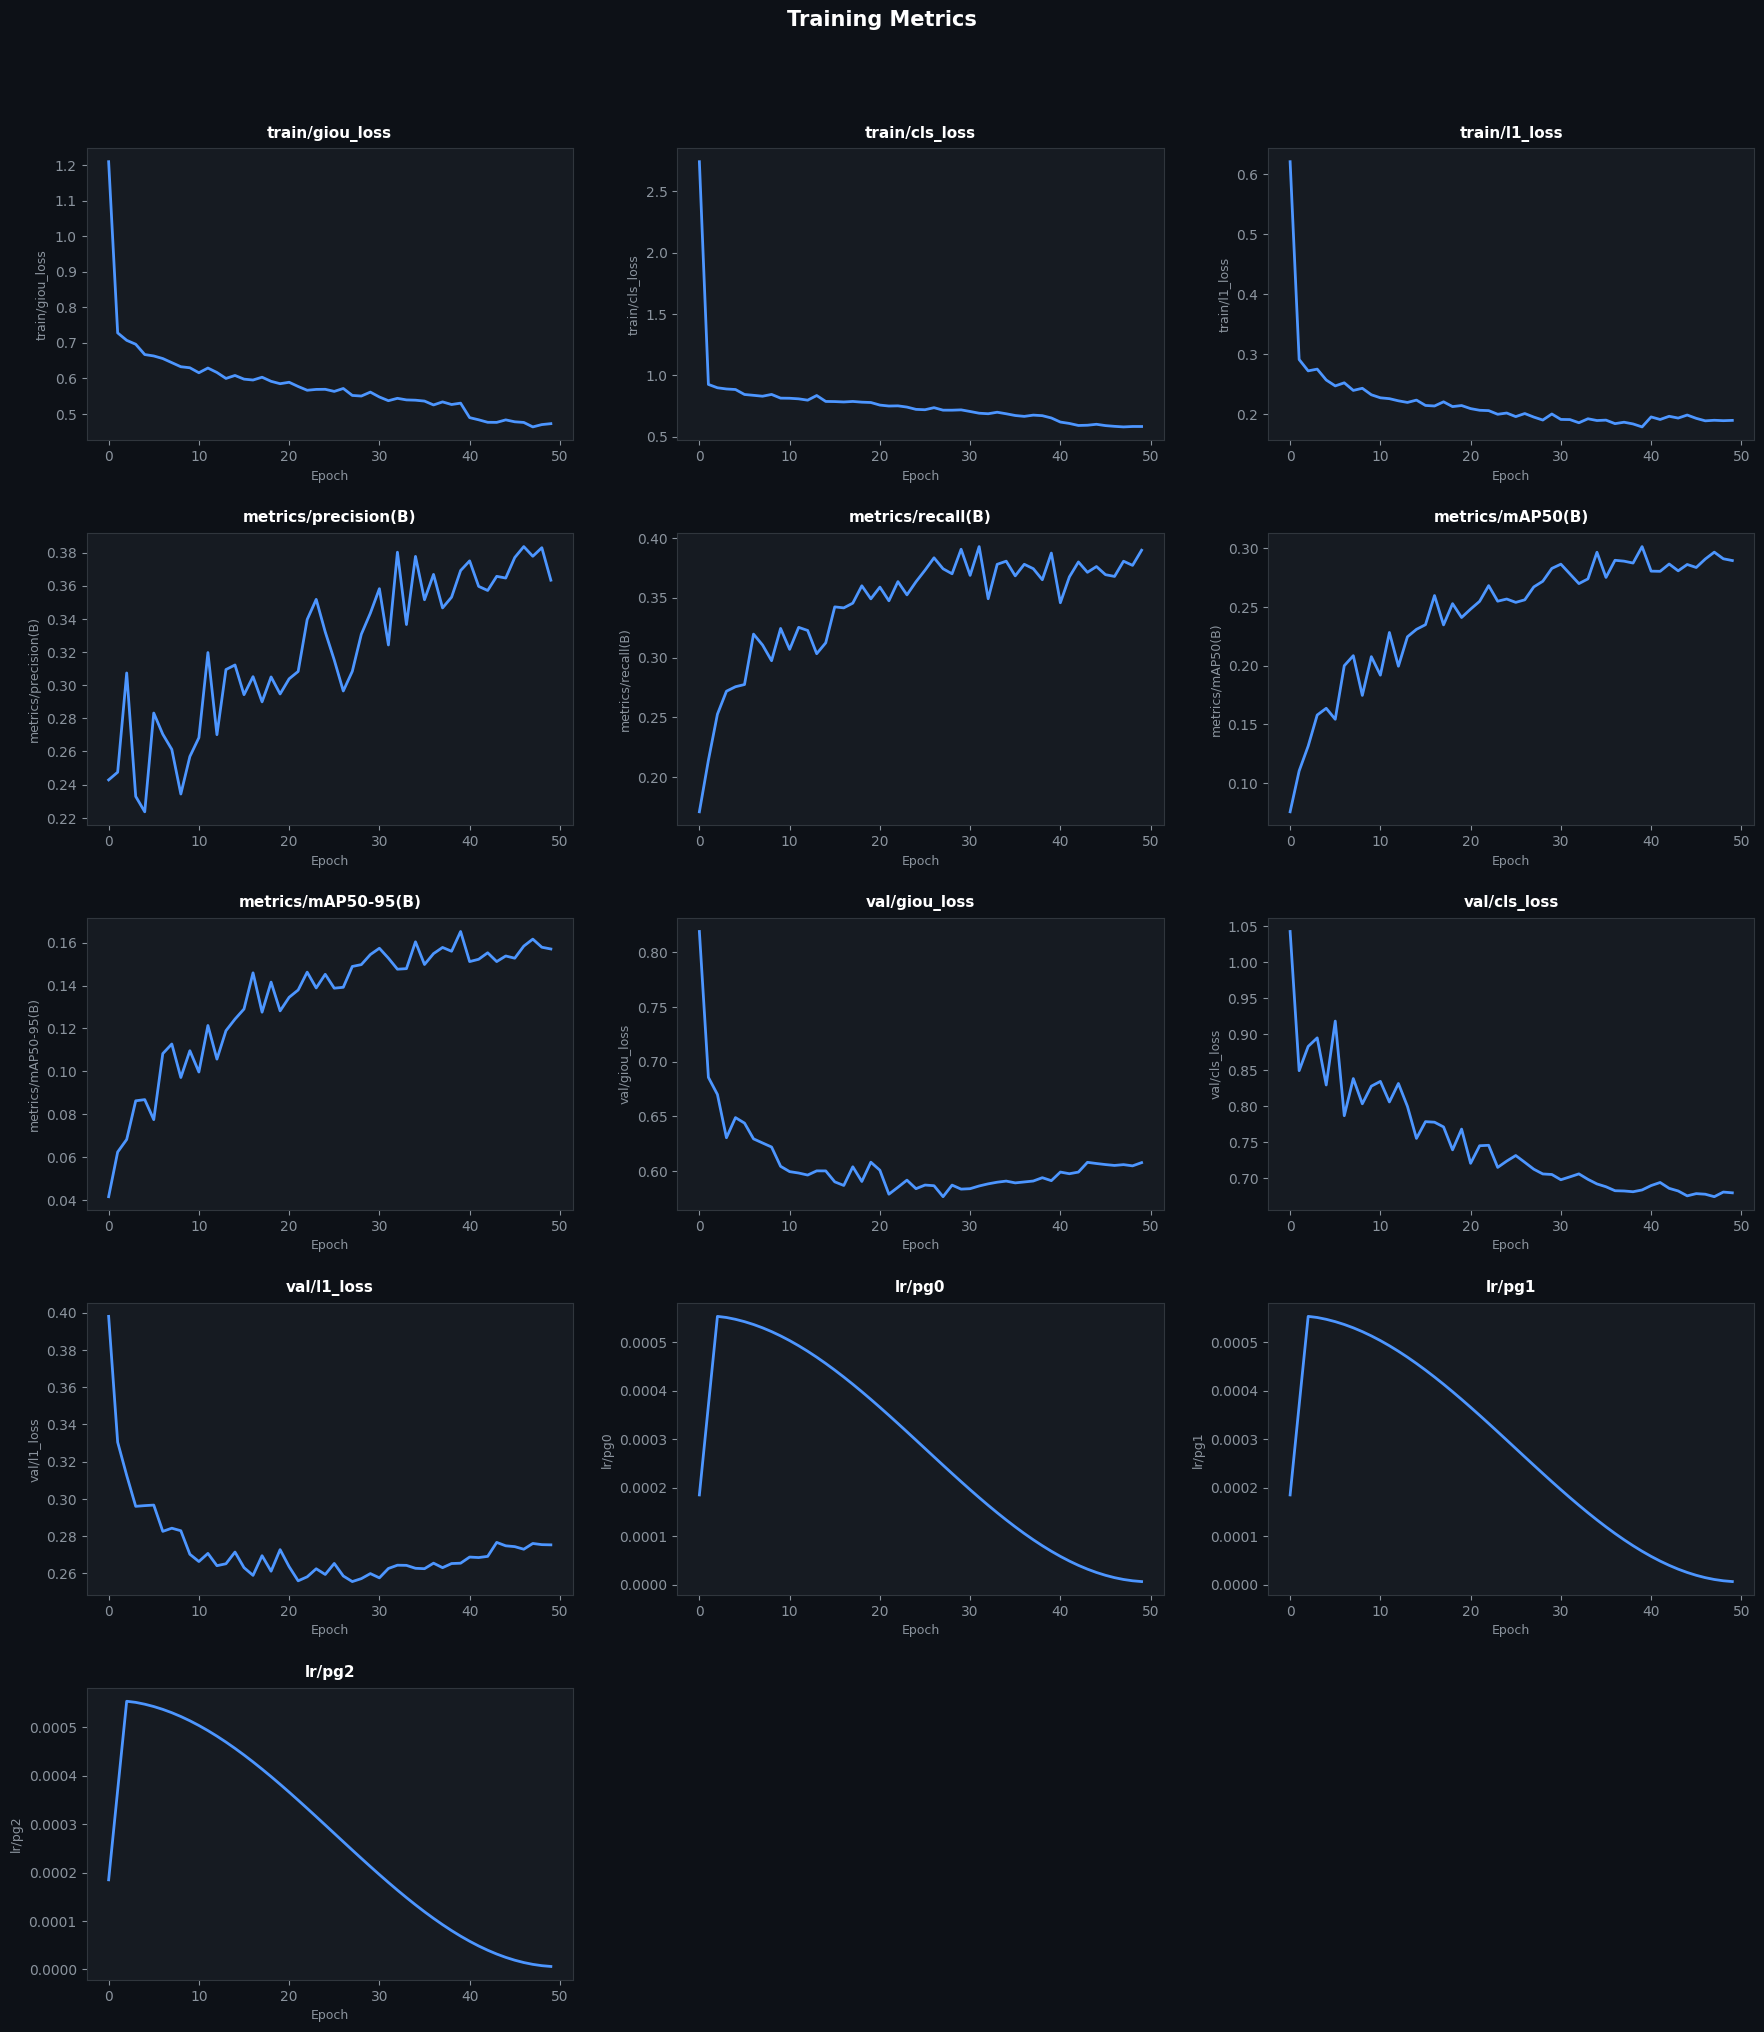

In [32]:
import math
metrics_df = track(RUN_DIR, RUN_NAME)
print(metrics_df.head())
plot_metrics(metrics_df)

**LOSS CURVE**
- **giou loss**: measures how well the predicted bounding boxes overlap with ground truth
- **cls loss**: measures how confidently the model assigns the right class to each box
- **l1 loss**: measures regression loss on the raw box coordinates.

**DETECTION METRICS**
- **Precision**: Of all boxes the model predicted, what fraction were correct.
- **Recall**: Of all real ground truth boxes, what fraction the model actually found.
- **mAP50** and **mAP50-95**: mAP for IOU >= 50, and from 50 to 95.

**Learning Rate**
- **Cosine learning rate schedule**: smooth cosine decay after warmup

## Visualize after training

In [33]:
# calculate accuracy
def compute_map(model, val_img_dir, val_lbl_dir, iou_threshold=0.4, conf_threshold=0.01):
    """
    Manually computes per-class AP and mAP using PASCAL VOC 2010 method
    (11-point interpolation) at a given IoU threshold.
    """
    from collections import defaultdict
    import numpy as np

    CLASS_NAMES = [
        "Aortic enlargement", "Atelectasis", "Calcification", "Cardiomegaly",
        "Consolidation", "ILD", "Infiltration", "Lung Opacity", "Nodule/Mass",
        "Other lesion", "Pleural effusion", "Pleural thickening",
        "Pneumothorax", "Pulmonary fibrosis",
    ]

    def iou(boxA, boxB):
        """Compute IoU between two boxes [x1,y1,x2,y2]."""
        xA = max(boxA[0], boxB[0])
        yA = max(boxA[1], boxB[1])
        xB = min(boxA[2], boxB[2])
        yB = min(boxA[3], boxB[3])
        interW = max(0, xB - xA)
        interH = max(0, yB - yA)
        inter  = interW * interH
        areaA  = (boxA[2]-boxA[0]) * (boxA[3]-boxA[1])
        areaB  = (boxB[2]-boxB[0]) * (boxB[3]-boxB[1])
        union  = areaA + areaB - inter
        return inter / union if union > 0 else 0.0

    def voc2010_ap(recalls, precisions):
        """
        PASCAL VOC 2010 AP: area under the precision-recall curve
        using all points (not just 11-point interpolation).
        Matches the method used in the VOC 2010+ challenge.
        """
        # Append sentinel values
        recalls    = np.concatenate(([0.0], recalls,    [1.0]))
        precisions = np.concatenate(([0.0], precisions, [0.0]))

        # Make precision monotonically decreasing (envelope)
        for i in range(len(precisions) - 2, -1, -1):
            precisions[i] = max(precisions[i], precisions[i + 1])

        # Integrate: sum area of rectangles where recall changes
        idxs = np.where(recalls[1:] != recalls[:-1])[0]
        ap = np.sum((recalls[idxs + 1] - recalls[idxs]) * precisions[idxs + 1])
        return float(ap)

    img_paths = sorted(Path(val_img_dir).glob("*.png"))

    # all_detections[cls] = list of (conf, is_tp) across all images
    # all_gt_counts[cls]  = total number of GT boxes for that class
    all_detections = defaultdict(list)
    all_gt_counts  = defaultdict(int)

    print(f"Running inference on {len(img_paths)} val images...")

    for img_path in img_paths:
        stem    = img_path.stem
        lbl_path = Path(val_lbl_dir) / f"{stem}.txt"

        # --- ground truth ---
        gt_by_class = defaultdict(list)
        if lbl_path.exists() and lbl_path.stat().st_size > 0:
            for line in lbl_path.read_text().strip().splitlines():
                parts  = line.split()
                cls    = int(parts[0])
                cx, cy, bw, bh = map(float, parts[1:5])
                # convert YOLO → absolute pixel coords
                img    = Image.open(img_path)
                W, H   = img.size
                x1 = (cx - bw/2) * W
                y1 = (cy - bh/2) * H
                x2 = (cx + bw/2) * W
                y2 = (cy + bh/2) * H
                gt_by_class[cls].append([x1, y1, x2, y2])
                all_gt_counts[cls] += 1

        # --- predictions ---
        results = model.predict(str(img_path), conf=conf_threshold, verbose=False)
        preds_by_class = defaultdict(list)
        for box in results[0].boxes:
            cls  = int(box.cls.item())
            conf = float(box.conf.item())
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            preds_by_class[cls].append((conf, [x1, y1, x2, y2]))

        # --- match predictions to GT per class ---
        all_classes = set(gt_by_class.keys()) | set(preds_by_class.keys())
        for cls in all_classes:
            gts      = gt_by_class[cls]           # list of [x1,y1,x2,y2]
            preds    = sorted(preds_by_class[cls], key=lambda x: -x[0])  # sort by conf desc
            matched  = [False] * len(gts)

            for conf, pred_box in preds:
                best_iou = 0.0
                best_idx = -1
                for j, gt_box in enumerate(gts):
                    if matched[j]:
                        continue
                    iou_val = iou(pred_box, gt_box)
                    if iou_val > best_iou:
                        best_iou = iou_val
                        best_idx = j

                if best_iou >= iou_threshold and best_idx >= 0:
                    matched[best_idx] = True
                    all_detections[cls].append((conf, 1))   # TP
                else:
                    all_detections[cls].append((conf, 0))   # FP

    # --- compute per-class AP ---
    print(f"\n{'─'*55}")
    print(f"  PASCAL VOC 2010 mAP  (IoU ≥ {iou_threshold})")
    print(f"{'─'*55}")
    print(f"  {'Class':<25} {'AP':>8}  {'GT':>6}  {'Preds':>6}")
    print(f"{'─'*55}")

    aps = []
    for cls in range(len(CLASS_NAMES)):
        n_gt = all_gt_counts.get(cls, 0)
        dets = all_detections.get(cls, [])

        if n_gt == 0:
            print(f"  {CLASS_NAMES[cls]:<25} {'N/A':>8}  {0:>6}  {len(dets):>6}  (no GT)")
            continue

        # sort all detections for this class by confidence descending
        dets = sorted(dets, key=lambda x: -x[0])
        tp_cumsum = np.cumsum([d[1]   for d in dets])
        fp_cumsum = np.cumsum([1-d[1] for d in dets])

        recalls    = tp_cumsum / n_gt
        precisions = tp_cumsum / (tp_cumsum + fp_cumsum + 1e-9)

        ap = voc2010_ap(recalls, precisions)
        aps.append(ap)
        print(f"  {CLASS_NAMES[cls]:<25} {ap:>8.4f}  {n_gt:>6}  {len(dets):>6}")

    mean_ap = np.mean(aps) if aps else 0.0
    print(f"{'─'*55}")
    print(f"  {'mAP':<25} {mean_ap:>8.4f}")
    print(f"{'─'*55}\n")

    return mean_ap, {CLASS_NAMES[cls]: ap for cls, ap in zip(range(len(CLASS_NAMES)), aps)}

In [34]:
map_score, per_class_ap = compute_map(
    model,
    val_img_dir   = WORK_DIR / "images" / "val",
    val_lbl_dir   = WORK_DIR / "labels" / "val",
    iou_threshold = 0.4,
)

Running inference on 1286 val images...

───────────────────────────────────────────────────────
  PASCAL VOC 2010 mAP  (IoU ≥ 0.4)
───────────────────────────────────────────────────────
  Class                           AP      GT   Preds
───────────────────────────────────────────────────────
  Aortic enlargement          0.9124     791    4108
  Atelectasis                 0.3150      41     169
  Calcification               0.4068     124    2637
  Cardiomegaly                0.9121     585    4689
  Consolidation               0.3363      54     654
  ILD                         0.4495     172    8860
  Infiltration                0.3878     159    1973
  Lung Opacity                0.3906     309    4929
  Nodule/Mass                 0.4608     286   18486
  Other lesion                0.2025     273   47818
  Pleural effusion            0.6610     283    9717
  Pleural thickening          0.3702     621   27449
  Pneumothorax                0.6595      23    1240
  Pulmonary fi

In [35]:
# visualize samples
def visualize_predictions(model, val_img_dir, val_lbl_dir,
                           iou_threshold=0.4, conf_threshold=0.25,
                           n_success=4, n_failure=4, seed=42):
    """
    Shows side-by-side prediction vs ground truth for:
      - n_success: images where at least one pred matched a GT box (TP)
      - n_failure: images where no preds matched any GT box (FN/FP)
    """
    import random
    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.patches as patches
    from collections import defaultdict
    from PIL import Image

    CLASS_NAMES = [
        "Aortic enlargement", "Atelectasis", "Calcification", "Cardiomegaly",
        "Consolidation", "ILD", "Infiltration", "Lung Opacity", "Nodule/Mass",
        "Other lesion", "Pleural effusion", "Pleural thickening",
        "Pneumothorax", "Pulmonary fibrosis",
    ]
    COLORS = [
        "#FF6B6B","#FFD93D","#6BCB77","#4D96FF","#FF922B",
        "#CC5DE8","#20C997","#F06595","#74C0FC","#A9E34B",
        "#FF8787","#63E6BE","#FFA94D","#DA77F2",
    ]

    def iou(boxA, boxB):
        xA, yA = max(boxA[0], boxB[0]), max(boxA[1], boxB[1])
        xB, yB = min(boxA[2], boxB[2]), min(boxA[3], boxB[3])
        inter  = max(0, xB - xA) * max(0, yB - yA)
        areaA  = (boxA[2]-boxA[0]) * (boxA[3]-boxA[1])
        areaB  = (boxB[2]-boxB[0]) * (boxB[3]-boxB[1])
        union  = areaA + areaB - inter
        return inter / union if union > 0 else 0.0

    def draw_boxes(ax, boxes, color_fn, label_fn, alpha=1.0):
        for box in boxes:
            cls, x1, y1, x2, y2, extra = box
            color = color_fn(cls)
            rect  = patches.Rectangle(
                (x1, y1), x2-x1, y2-y1,
                linewidth=2, edgecolor=color, facecolor=color, alpha=0.12
            )
            ax.add_patch(rect)
            border = patches.Rectangle(
                (x1, y1), x2-x1, y2-y1,
                linewidth=2, edgecolor=color, facecolor="none", alpha=alpha
            )
            ax.add_patch(border)
            ax.text(
                x1+3, y1-6, label_fn(cls, extra),
                color="white", fontsize=7, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor=color,
                          alpha=0.9, linewidth=0)
            )

    # ── Scan val images and classify as success / failure ────────────────────
    img_paths  = sorted(Path(val_img_dir).glob("*.png"))
    successes  = []   # (img_path, gt_boxes, pred_boxes)
    failures   = []

    random.seed(seed)
    random.shuffle(img_paths)

    for img_path in img_paths:
        if len(successes) >= n_success * 4 and len(failures) >= n_failure * 4:
            break

        stem     = img_path.stem
        lbl_path = Path(val_lbl_dir) / f"{stem}.txt"

        img    = Image.open(img_path).convert("RGB")
        W, H   = img.size
        scaled = img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

        # parse GT
        gt_boxes = []
        if lbl_path.exists() and lbl_path.stat().st_size > 0:
            for line in lbl_path.read_text().strip().splitlines():
                parts       = line.split()
                cls         = int(parts[0])
                cx,cy,bw,bh = map(float, parts[1:5])
                x1 = (cx - bw/2) * IMG_SIZE
                y1 = (cy - bh/2) * IMG_SIZE
                x2 = (cx + bw/2) * IMG_SIZE
                y2 = (cy + bh/2) * IMG_SIZE
                gt_boxes.append((cls, x1, y1, x2, y2, None))

        if not gt_boxes:
            continue  # skip no-finding images

        # run prediction
        results   = model.predict(str(img_path), conf=conf_threshold, verbose=False)
        pred_boxes = []
        for box in results[0].boxes:
            cls        = int(box.cls.item())
            conf       = float(box.conf.item())
            coords     = box.xyxy[0].tolist()
            # scale preds from original → IMG_SIZE space
            sx, sy     = IMG_SIZE / W, IMG_SIZE / H
            x1,y1,x2,y2 = coords[0]*sx, coords[1]*sy, coords[2]*sx, coords[3]*sy
            pred_boxes.append((cls, x1, y1, x2, y2, conf))

        # check if any pred matches any GT at given IoU
        matched = False
        for (pcls, px1,py1,px2,py2, conf) in pred_boxes:
            for (gcls, gx1,gy1,gx2,gy2, _) in gt_boxes:
                if pcls == gcls and iou([px1,py1,px2,py2],[gx1,gy1,gx2,gy2]) >= iou_threshold:
                    matched = True
                    break
            if matched:
                break

        entry = (scaled, gt_boxes, pred_boxes)
        if matched and len(successes) < n_success * 4:
            successes.append(entry)
        elif not matched and len(failures) < n_failure * 4:
            failures.append(entry)

    # ── Plot ─────────────────────────────────────────────────────────────────
    def plot_section(samples, title, accent, n):
        samples = samples[:n]
        fig, axes = plt.subplots(n, 2, figsize=(14, n * 5))
        if n == 1:
            axes = [axes]
        fig.patch.set_facecolor("#0d1117")
        fig.suptitle(title, color=accent, fontsize=15,
                     fontweight="bold", y=1.01)

        axes[0][0].set_title("Ground Truth",  color="white", fontsize=11, pad=8)
        axes[0][1].set_title("Predictions",   color="white", fontsize=11, pad=8)

        for row, (img, gts, preds) in enumerate(samples):
            for col, (boxes, box_label) in enumerate([
                (gts,   lambda c, _:  CLASS_NAMES[c] if c < len(CLASS_NAMES) else f"cls_{c}"),
                (preds, lambda c, cf: f"{CLASS_NAMES[c] if c < len(CLASS_NAMES) else f'cls_{c}'} {cf:.2f}"),
            ]):
                ax = axes[row][col]
                ax.imshow(img)
                draw_boxes(ax, boxes,
                           color_fn=lambda c: COLORS[c % len(COLORS)],
                           label_fn=box_label)
                ax.set_xticks([]); ax.set_yticks([])
                ax.set_facecolor("#161b22")
                for spine in ax.spines.values():
                    spine.set_edgecolor("#30363d")

            gt_classes   = [CLASS_NAMES[b[0]] for b in gts]
            pred_classes = [CLASS_NAMES[b[0]] for b in preds] if preds else ["(none)"]
            axes[row][0].set_xlabel(f"GT: {', '.join(set(gt_classes))}",
                                    color="#8b949e", fontsize=8)
            axes[row][1].set_xlabel(f"Pred: {', '.join(set(pred_classes))}",
                                    color="#8b949e", fontsize=8)

        plt.tight_layout(pad=2.0)
        plt.show()

    plot_section(successes, f"✅  Successful Predictions  (IoU ≥ {iou_threshold})",
                 accent="#6BCB77", n=n_success)
    plot_section(failures,  f"❌  Failed Predictions  (IoU < {iou_threshold})",
                 accent="#FF6B6B", n=n_failure)

    print(f"Found {len(successes)} successes and {len(failures)} failures "
          f"from {len(img_paths)} val images scanned.")

/tmp/ipykernel_57/716109430.py:157: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(pad=2.0)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


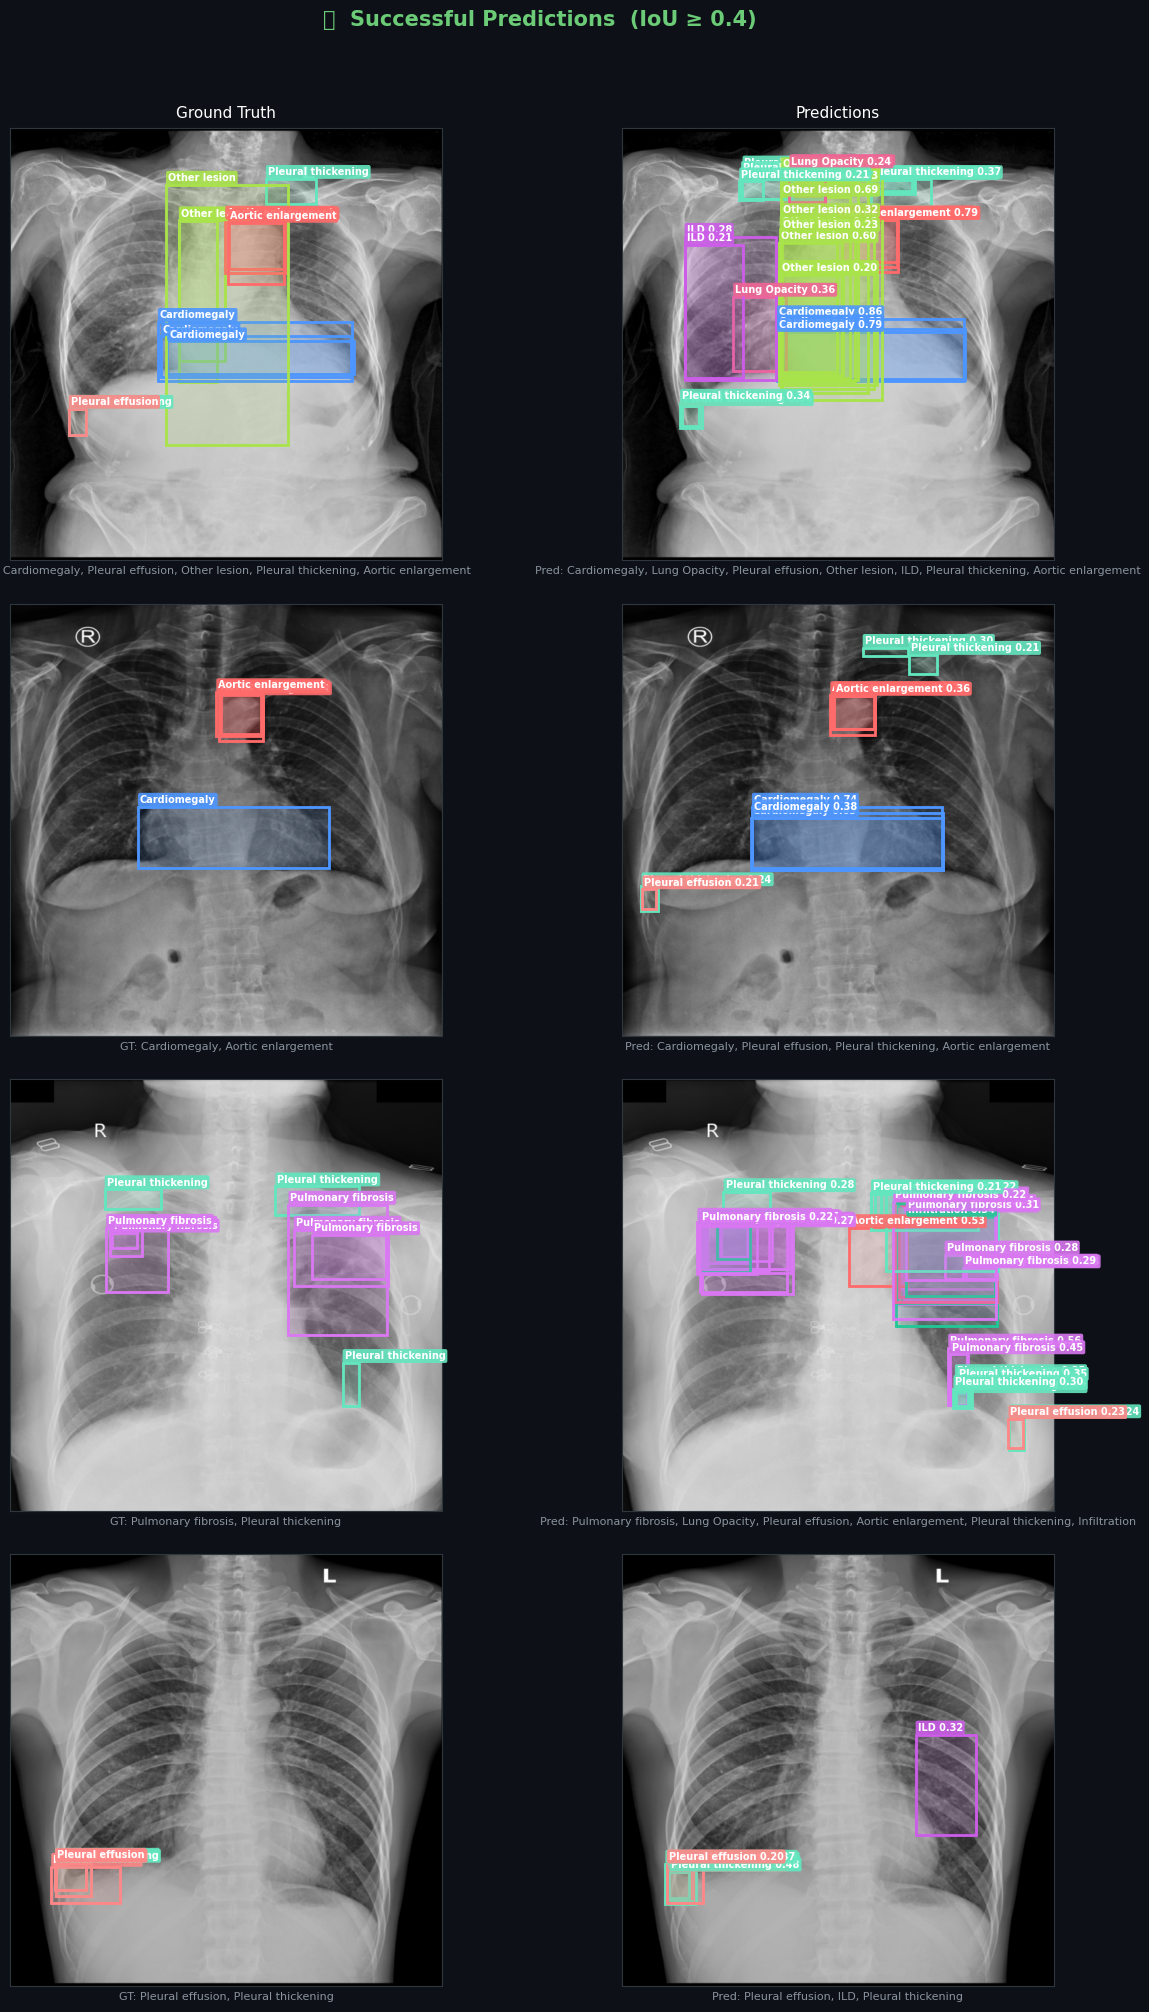

/tmp/ipykernel_57/716109430.py:157: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(pad=2.0)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


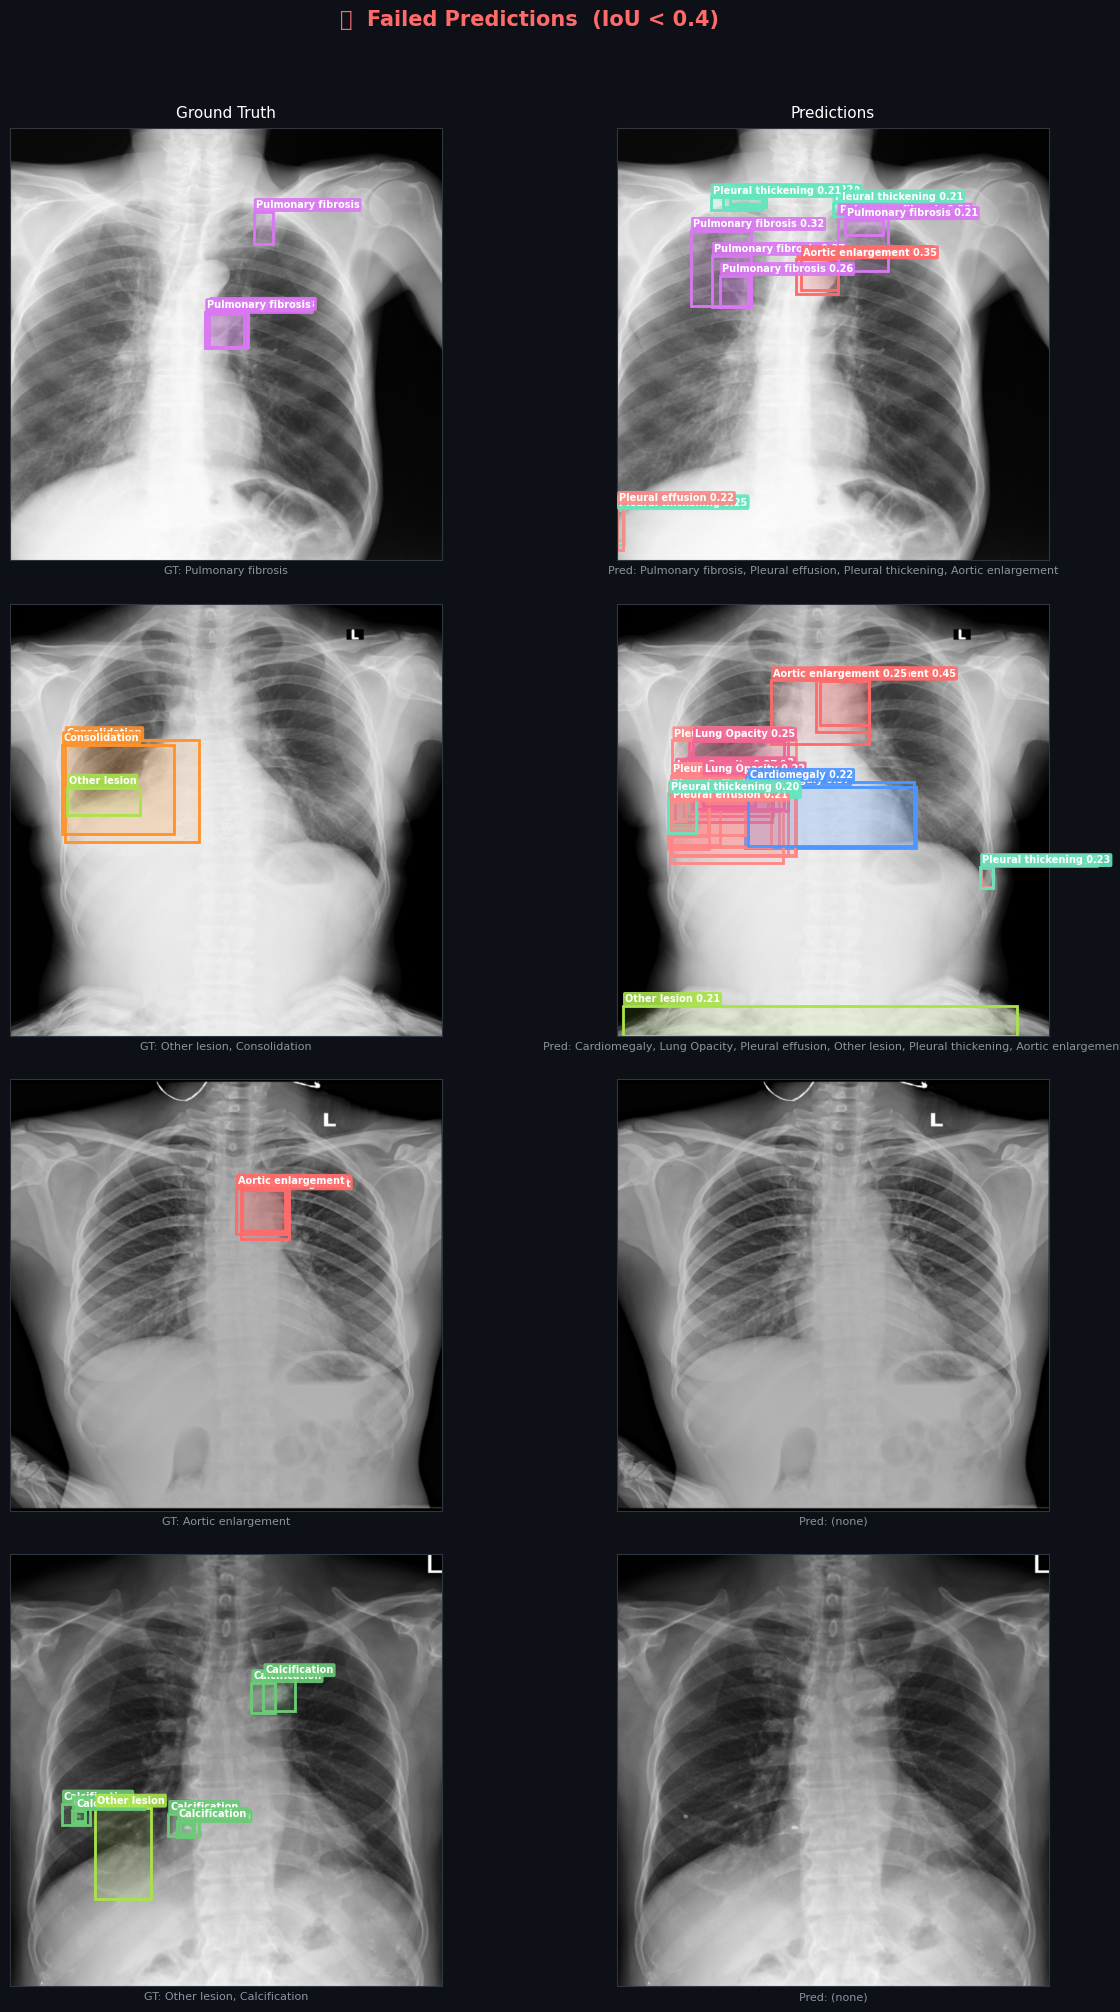

Found 16 successes and 6 failures from 1286 val images scanned.


In [36]:
visualize_predictions(
    model,
    val_img_dir   = WORK_DIR / "images" / "val",
    val_lbl_dir   = WORK_DIR / "labels" / "val",
    iou_threshold = 0.4,
    conf_threshold = 0.2,
    n_success = 4,
    n_failure = 4,
)

In [37]:
def visualize_class_analysis(per_class_ap, model, val_img_dir, val_lbl_dir,
                              iou_threshold=0.4, conf_threshold=0.25):
    """
    Three-part class-level analysis:
      1. AP bar chart per class (sorted best → worst)
      2. Confusion-style matrix: for each GT class, what did the model predict?
      3. Per-class FP/FN breakdown bar chart
    """
    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.patches as patches
    from collections import defaultdict
    from PIL import Image

    CLASS_NAMES = [
        "Aortic enlargement", "Atelectasis", "Calcification", "Cardiomegaly",
        "Consolidation", "ILD", "Infiltration", "Lung Opacity", "Nodule/Mass",
        "Other lesion", "Pleural effusion", "Pleural thickening",
        "Pneumothorax", "Pulmonary fibrosis",
    ]
    COLORS = [
        "#FF6B6B","#FFD93D","#6BCB77","#4D96FF","#FF922B",
        "#CC5DE8","#20C997","#F06595","#74C0FC","#A9E34B",
        "#FF8787","#63E6BE","#FFA94D","#DA77F2",
    ]
    N = len(CLASS_NAMES)

    def iou(boxA, boxB):
        xA, yA = max(boxA[0], boxB[0]), max(boxA[1], boxB[1])
        xB, yB = min(boxA[2], boxB[2]), min(boxA[3], boxB[3])
        inter  = max(0, xB-xA) * max(0, yB-yA)
        areaA  = (boxA[2]-boxA[0]) * (boxA[3]-boxA[1])
        areaB  = (boxB[2]-boxB[0]) * (boxB[3]-boxB[1])
        union  = areaA + areaB - inter
        return inter / union if union > 0 else 0.0

    # ── 1. AP Bar Chart ───────────────────────────────────────────────────────
    ap_items = sorted(per_class_ap.items(), key=lambda x: -x[1])
    names    = [x[0] for x in ap_items]
    aps      = [x[1] for x in ap_items]
    bar_colors = ["#6BCB77" if a >= 0.5 else "#FFD93D" if a >= 0.25 else "#FF6B6B"
                  for a in aps]

    fig, ax = plt.subplots(figsize=(14, 6))
    fig.patch.set_facecolor("#0d1117")
    ax.set_facecolor("#161b22")
    bars = ax.barh(names, aps, color=bar_colors, edgecolor="#30363d", height=0.65)
    ax.axvline(np.mean(aps), color="white", linewidth=1.5,
               linestyle="--", label=f"mAP = {np.mean(aps):.3f}")
    for bar, val in zip(bars, aps):
        ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
                f"{val:.3f}", va="center", color="white", fontsize=9)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel("Average Precision", color="#8b949e")
    ax.set_title("Per-Class AP  (green ≥ 0.5 · yellow ≥ 0.25 · red < 0.25)",
                 color="white", fontsize=13, fontweight="bold", pad=10)
    ax.tick_params(colors="#8b949e")
    ax.legend(facecolor="#0d1117", labelcolor="white", fontsize=10)
    for spine in ax.spines.values():
        spine.set_edgecolor("#30363d")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

    # ── Collect confusion data + FP/FN counts ────────────────────────────────
    # confusion[gt_cls][pred_cls] = number of times a GT box of gt_cls
    #                                was matched by a pred of pred_cls
    confusion  = np.zeros((N, N), dtype=int)
    fn_counts  = defaultdict(int)   # GT boxes with no matching pred
    fp_counts  = defaultdict(int)   # Pred boxes with no matching GT
    tp_counts  = defaultdict(int)

    img_paths = sorted(Path(val_img_dir).glob("*.png"))

    for img_path in img_paths:
        stem     = img_path.stem
        lbl_path = Path(val_lbl_dir) / f"{stem}.txt"

        img  = Image.open(img_path).convert("RGB")
        W, H = img.size

        gt_boxes = []
        if lbl_path.exists() and lbl_path.stat().st_size > 0:
            for line in lbl_path.read_text().strip().splitlines():
                parts       = line.split()
                cls         = int(parts[0])
                cx,cy,bw,bh = map(float, parts[1:5])
                x1=(cx-bw/2)*IMG_SIZE; y1=(cy-bh/2)*IMG_SIZE
                x2=(cx+bw/2)*IMG_SIZE; y2=(cy+bh/2)*IMG_SIZE
                gt_boxes.append([cls, x1, y1, x2, y2])

        if not gt_boxes:
            continue

        results = model.predict(str(img_path), conf=conf_threshold, verbose=False)
        pred_boxes = []
        for box in results[0].boxes:
            cls        = int(box.cls.item())
            sx, sy     = IMG_SIZE/W, IMG_SIZE/H
            x1,y1,x2,y2 = [c*s for c,s in zip(box.xyxy[0].tolist(),
                                                [sx,sy,sx,sy])]
            pred_boxes.append([cls, x1, y1, x2, y2])

        gt_matched   = [False] * len(gt_boxes)
        pred_matched = [False] * len(pred_boxes)

        # match by IoU regardless of class first (to detect class confusions)
        iou_matrix = np.zeros((len(gt_boxes), len(pred_boxes)))
        for i, gt in enumerate(gt_boxes):
            for j, pred in enumerate(pred_boxes):
                iou_matrix[i, j] = iou(gt[1:], pred[1:])

        # greedy match: highest IoU first
        flat_order = np.argsort(-iou_matrix.ravel())
        for idx in flat_order:
            i, j = divmod(idx, max(len(pred_boxes), 1))
            if i >= len(gt_boxes) or j >= len(pred_boxes):
                continue
            if gt_matched[i] or pred_matched[j]:
                continue
            if iou_matrix[i, j] >= iou_threshold:
                gt_cls   = gt_boxes[i][0]
                pred_cls = pred_boxes[j][0]
                confusion[gt_cls][pred_cls] += 1
                gt_matched[i]   = True
                pred_matched[j] = True
                tp_counts[gt_cls] += 1

        for i, gt in enumerate(gt_boxes):
            if not gt_matched[i]:
                fn_counts[gt[0]] += 1

        for j, pred in enumerate(pred_boxes):
            if not pred_matched[j]:
                fp_counts[pred[0]] += 1

    # ── 2. Confusion Matrix ───────────────────────────────────────────────────
    short = [n.split()[0] for n in CLASS_NAMES]   # first word only for axis

    fig, ax = plt.subplots(figsize=(15, 12))
    fig.patch.set_facecolor("#0d1117")
    ax.set_facecolor("#0d1117")

    # normalise rows (per GT class)
    row_sums = confusion.sum(axis=1, keepdims=True).clip(min=1)
    norm     = confusion / row_sums

    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02).ax.yaxis.set_tick_params(color="white")

    for i in range(N):
        for j in range(N):
            val = confusion[i, j]
            if val > 0:
                text_color = "white" if norm[i, j] < 0.6 else "#0d1117"
                ax.text(j, i, str(val), ha="center", va="center",
                        fontsize=8, color=text_color, fontweight="bold")

    ax.set_xticks(range(N)); ax.set_xticklabels(short, rotation=45,
                                                  ha="right", color="#8b949e", fontsize=9)
    ax.set_yticks(range(N)); ax.set_yticklabels(short, color="#8b949e", fontsize=9)
    ax.set_xlabel("Predicted Class", color="#8b949e", labelpad=10)
    ax.set_ylabel("Ground Truth Class", color="#8b949e", labelpad=10)
    ax.set_title("Confusion Matrix — GT vs Predicted Class  (IoU-matched, row-normalised)",
                 color="white", fontsize=13, fontweight="bold", pad=12)
    for spine in ax.spines.values():
        spine.set_edgecolor("#30363d")
    plt.tight_layout()
    plt.show()

    # ── 3. TP / FP / FN breakdown ────────────────────────────────────────────
    tps = [tp_counts.get(i, 0) for i in range(N)]
    fps = [fp_counts.get(i, 0) for i in range(N)]
    fns = [fn_counts.get(i, 0) for i in range(N)]

    x   = np.arange(N)
    w   = 0.28

    fig, ax = plt.subplots(figsize=(16, 6))
    fig.patch.set_facecolor("#0d1117")
    ax.set_facecolor("#161b22")

    ax.bar(x - w, tps, w, label="TP",  color="#6BCB77", edgecolor="#30363d")
    ax.bar(x,     fps, w, label="FP",  color="#FFD93D", edgecolor="#30363d")
    ax.bar(x + w, fns, w, label="FN",  color="#FF6B6B", edgecolor="#30363d")

    ax.set_xticks(x)
    ax.set_xticklabels(short, rotation=45, ha="right", color="#8b949e", fontsize=9)
    ax.set_ylabel("Box Count", color="#8b949e")
    ax.set_title("Per-Class TP / FP / FN Breakdown",
                 color="white", fontsize=13, fontweight="bold", pad=10)
    ax.tick_params(colors="#8b949e")
    ax.legend(facecolor="#0d1117", labelcolor="white", fontsize=10)
    for spine in ax.spines.values():
        spine.set_edgecolor("#30363d")
    plt.tight_layout()
    plt.show()

    # ── Print common mistakes ─────────────────────────────────────────────────
    print("=" * 55)
    print("  COMMON PREDICTION MISTAKES")
    print("=" * 55)
    print(f"\n  {'Class':<25} {'TP':>5} {'FP':>5} {'FN':>5}  Precision  Recall")
    print(f"  {'─'*53}")
    for i in range(N):
        tp, fp, fn = tps[i], fps[i], fns[i]
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        print(f"  {CLASS_NAMES[i]:<25} {tp:>5} {fp:>5} {fn:>5}  "
              f"{prec:>8.3f}   {rec:>5.3f}")

    print(f"\n  Top class confusions (GT → predicted as):")
    off_diag = [(confusion[i,j], i, j)
                for i in range(N) for j in range(N) if i != j and confusion[i,j] > 0]
    for count, gt_c, pred_c in sorted(off_diag, reverse=True)[:8]:
        print(f"    {CLASS_NAMES[gt_c]:<25} → {CLASS_NAMES[pred_c]:<25}  ({count}x)")
    print("=" * 55)

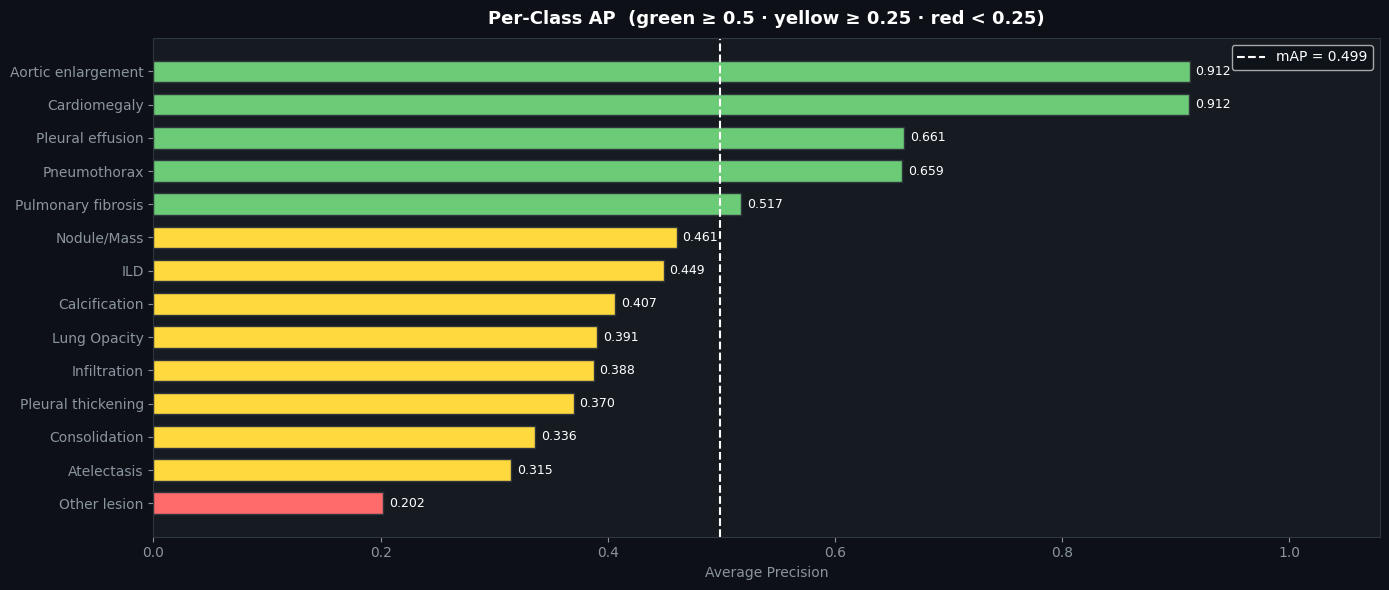

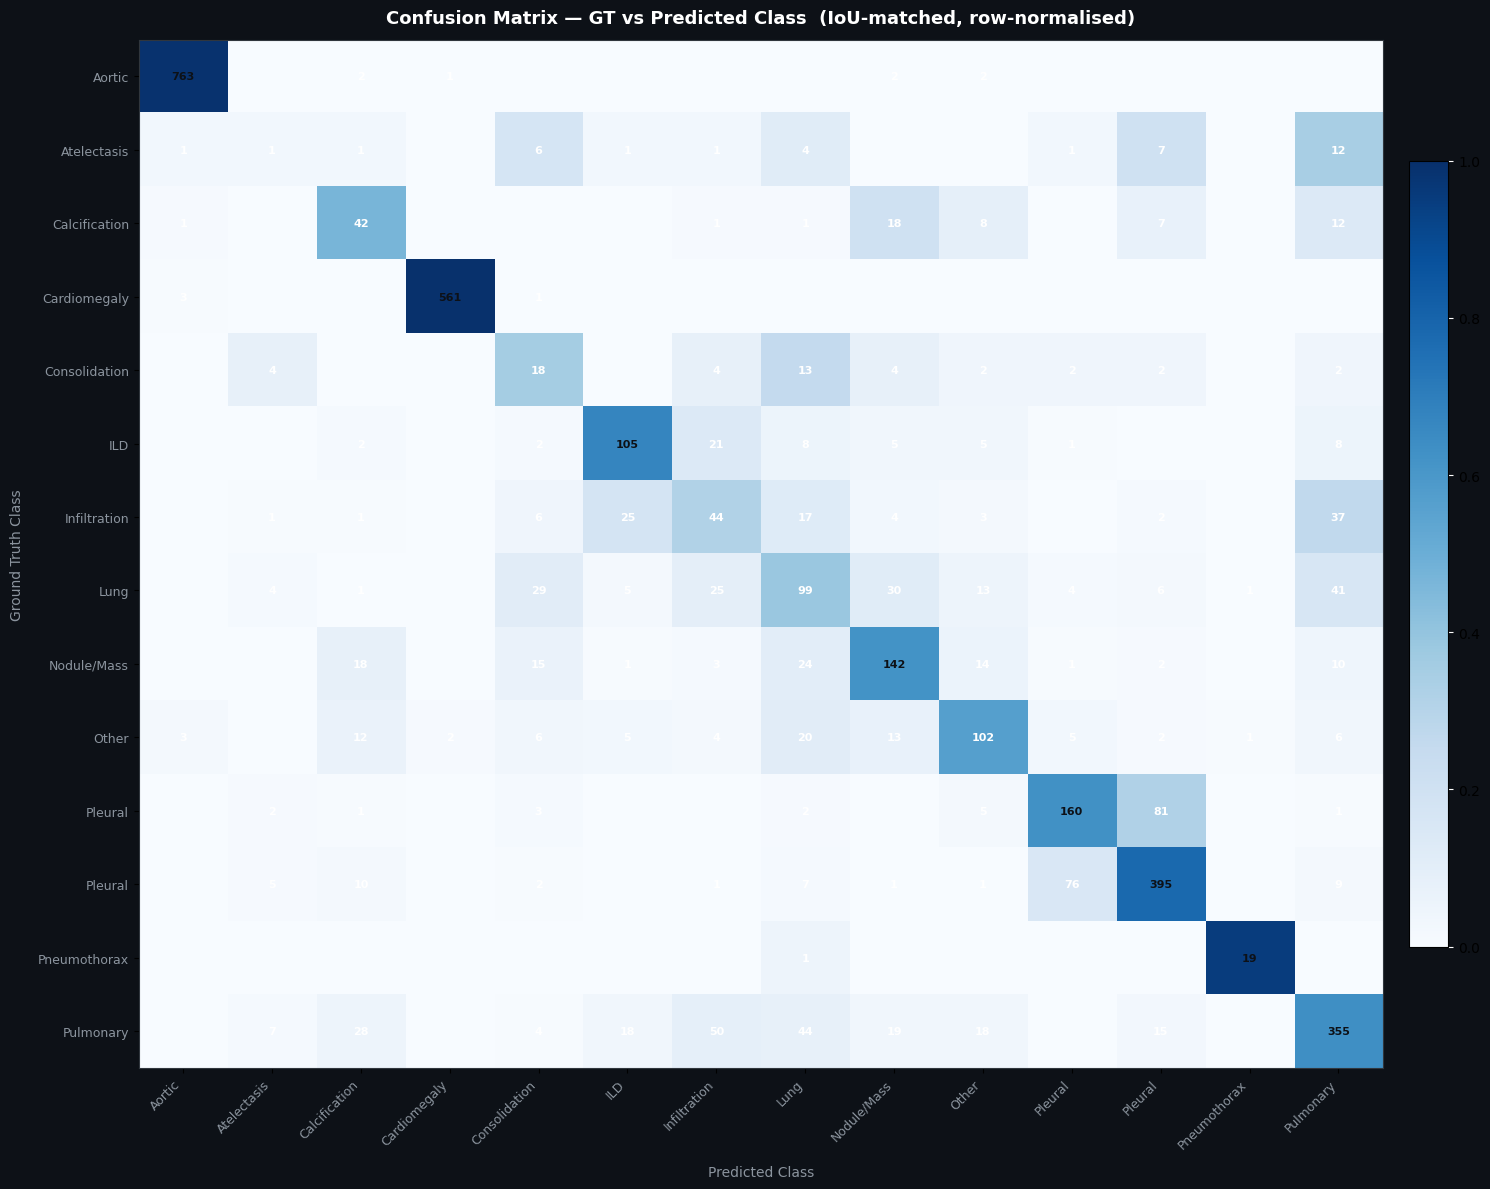

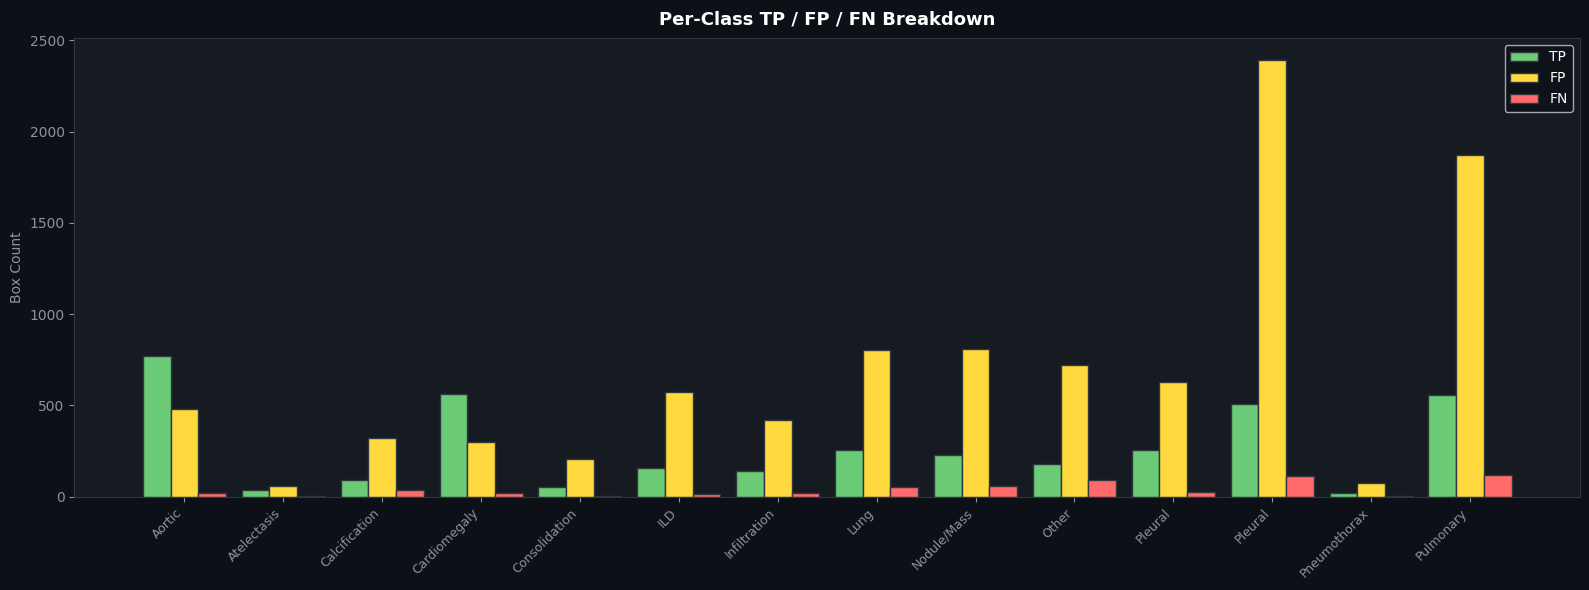

  COMMON PREDICTION MISTAKES

  Class                        TP    FP    FN  Precision  Recall
  ─────────────────────────────────────────────────────
  Aortic enlargement          770   479    21     0.616   0.973
  Atelectasis                  35    60     6     0.368   0.854
  Calcification                90   322    34     0.218   0.726
  Cardiomegaly                565   297    20     0.655   0.966
  Consolidation                51   209     3     0.196   0.944
  ILD                         157   573    15     0.215   0.913
  Infiltration                140   420    19     0.250   0.881
  Lung Opacity                258   806    51     0.242   0.835
  Nodule/Mass                 230   807    56     0.222   0.804
  Other lesion                181   723    92     0.200   0.663
  Pleural effusion            255   627    28     0.289   0.901
  Pleural thickening          507  2394   114     0.175   0.816
  Pneumothorax                 20    75     3     0.211   0.870
  Pulmonary fibro

In [38]:
visualize_class_analysis(
    per_class_ap, model,
    val_img_dir    = WORK_DIR / "images" / "val",
    val_lbl_dir    = WORK_DIR / "labels" / "val",
    iou_threshold  = 0.4,
    conf_threshold = 0.2,
)

## Save Models to hugging face

In [51]:
"""
Run this after having a good model 
This saves the model to huggingface so the model can be reused after the current session ends.
"""

import os
from huggingface_hub import HfApi, hf_hub_download
from pathlib import Path

from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
REPO_ID = "jc253/amia-rtdetr-checkpoints"

def save_model(local_path):
    """Call this after training to push best.pt to HuggingFace."""
    api = HfApi()
    api.upload_file(
        path_or_fileobj=str(local_path),
        path_in_repo=Path(local_path).name,
        repo_id=REPO_ID,
        repo_type="model",
        token=HF_TOKEN,
    )
    print(f"Saved to HuggingFace: {REPO_ID}")

def load_model():
    """Call this at the top of a new session to resume."""
    dst = Path("/kaggle/working/checkpoints")
    dst.mkdir(exist_ok=True)
    try:
        hf_hub_download(
            repo_id=REPO_ID,
            filename="last.pt",
            local_dir=str(dst),
            token=HF_TOKEN,
        )
        print("Loaded checkpoint from HuggingFace")
        return dst / "last.pt"
    except Exception:
        print("No checkpoint found, starting fresh")
        return None

In [52]:
# Save after training completes
save_model(Path(RUN_DIR / RUN_NAME / "weights" / "best.pt"))
save_model(Path(RUN_DIR / RUN_NAME / "weights" / "last.pt"))

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

No files have been modified since last commit. Skipping to prevent empty commit.


Saved to HuggingFace: jc253/amia-rtdetr-checkpoints


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

No files have been modified since last commit. Skipping to prevent empty commit.


Saved to HuggingFace: jc253/amia-rtdetr-checkpoints
